In [1]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')

print(f'Train: {train.shape}  |  Test: {test.shape}')
print(f'Missing values in train:\n{train.isnull().sum()[train.isnull().sum() > 0]}')
print(f'Missing values in test:\n{test.isnull().sum()[test.isnull().sum() > 0]}')

Train: (699635, 23)  |  Test: (299844, 22)
Missing values in train:
Arrival Delay in Minutes    292
dtype: int64
Missing values in test:
Arrival Delay in Minutes    130
dtype: int64


In [2]:
print(train.nunique())

id                                   699635
Age                                      75
Flight Distance                        3474
Inflight wifi service                     6
Departure/Arrival time convenient         6
Ease of Online booking                    6
Gate location                             6
Food and drink                            6
Online boarding                           6
Seat comfort                              6
Inflight entertainment                    6
On-board service                          6
Leg room service                          6
Baggage handling                          5
Checkin service                           6
Cleanliness                               6
Departure Delay in Minutes              167
Arrival Delay in Minutes                168
Gender                                    2
Customer Type                             2
Type of Travel                            2
Class                                     3
satisfaction                    

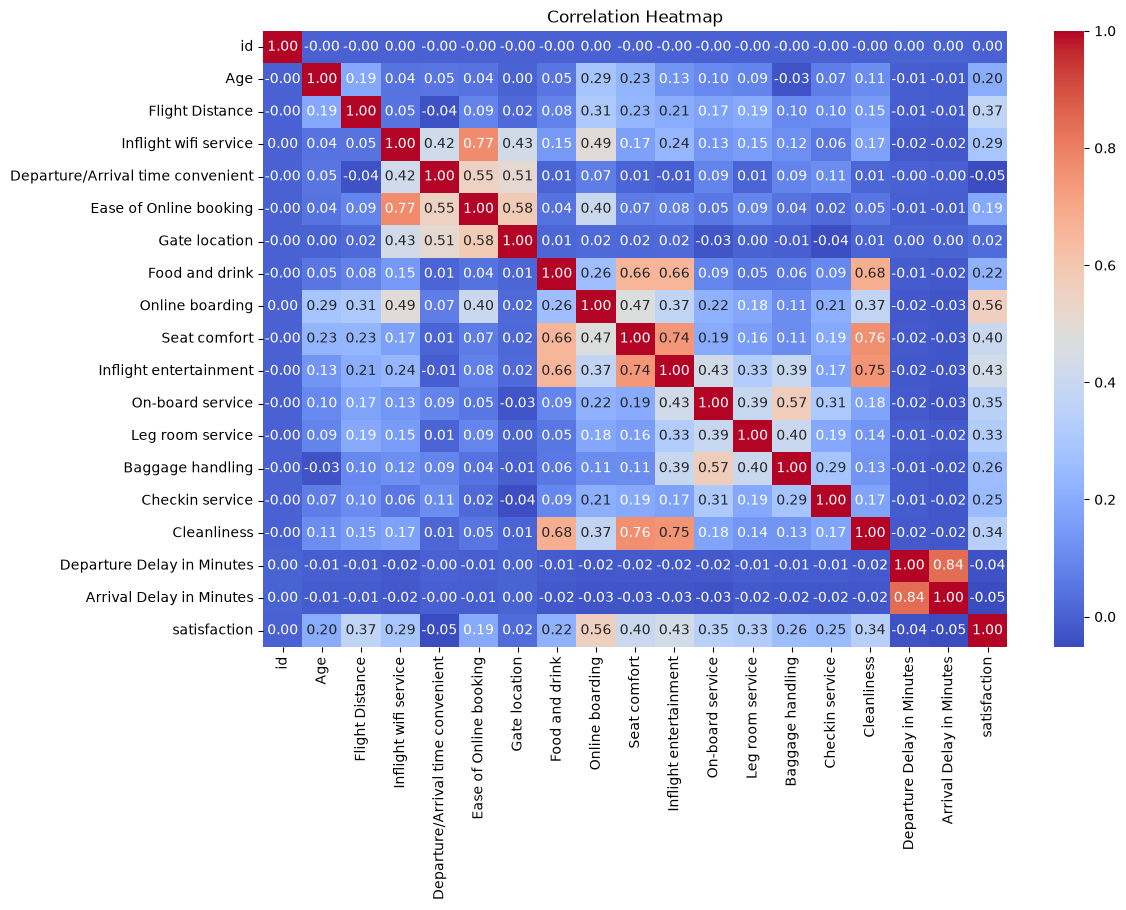

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.heatmap(
    train.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [4]:
train.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.00000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.00000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.37213,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.00000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.50000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.00000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.50000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.00000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


In [5]:
df = train
train.info()


<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

In [ ]:
!pip install PyIMSL

In [ ]:
import numpy as np
import pandas as pd
import imsl.data_mining as dm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report

# Separate features and target
X = df.drop(columns=["satisfaction"]).copy()
y = df["satisfaction"].copy()

numerical_cols = [
    "Age", "Flight Distance",
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking", "Gate location",
    "Food and drink", "Online boarding", "Seat comfort",
    "Inflight entertainment", "On-board service",
    "Leg room service", "Baggage handling",
    "Checkin service", "Cleanliness",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

categorical_cols = [
    "Gender", "Type of Travel", "Class", "Customer Type"
]

# Encode target
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Impute numerical features
num_imputer = SimpleImputer(strategy="median")
X_train_num = num_imputer.fit_transform(X_train[numerical_cols])
X_test_num = num_imputer.transform(X_test[numerical_cols])

# Impute and encode categorical features
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_cat = cat_imputer.fit_transform(X_train[categorical_cols])
X_test_cat = cat_imputer.transform(X_test[categorical_cols])

cat_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)
X_train_cat = cat_encoder.fit_transform(X_train_cat)
X_test_cat = cat_encoder.transform(X_test_cat)

# Combine features
X_train_processed = np.column_stack([
    X_train_num, X_train_cat
]).astype(float)

X_test_processed = np.column_stack([
    X_test_num, X_test_cat
]).astype(float)

# QUEST expects the response column in the data matrix.
# Put target first, followed by the predictors.
train_matrix = np.column_stack([
    y_train, X_train_processed
]).astype(float)

# Response is categorical; numerical predictors are quantitative;
# categorical predictors are categorical.
var_type = np.array(
    [0] + [2] * len(numerical_cols) + [0] * len(categorical_cols),
    dtype=int
)

# Train QUEST
with dm.QUESTDecisionTree(
    response_col_idx=0,
    var_type=var_type,
    alpha=0.05,
    min_n_node=20,
    min_split=40,
    max_size=100,
    max_depth=10,
    response_name="satisfaction",
    var_names=tuple(numerical_cols + categorical_cols),
    class_names=tuple(str(c) for c in target_encoder.classes_)
) as quest_model:

    quest_model.train(train_matrix)

    # Provide a placeholder response column; actual labels are not
    # used as predictors by QUEST.
    test_matrix = np.column_stack([
        np.zeros(len(X_test_processed)),
        X_test_processed
    ])

    result = quest_model.predict(test_matrix)
    y_pred = np.asarray(result.predictions).astype(int)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(target_encoder.classes_)),
        target_names=[str(c) for c in target_encoder.classes_],
        zero_division=0
    ))

    print(quest_model)

ModuleNotFoundError: No module named 'imsl'

In [6]:
df.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='str')

In [7]:
df

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,699630,57,612,2,1,1,1,1,3,3,...,2,2,4,0,0.0,Female,Loyal Customer,Business travel,Eco,False
699631,699631,30,862,2,2,2,3,4,2,4,...,4,2,4,24,34.0,Female,disloyal Customer,Business travel,Eco,False
699632,699632,49,3148,5,5,5,5,4,4,4,...,5,5,5,0,0.0,Male,Loyal Customer,Business travel,Business,True
699633,699633,61,679,5,2,2,2,5,4,4,...,5,5,1,0,0.0,Female,Loyal Customer,Business travel,Eco,True


In [8]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

In [9]:
# Separate features and target
X = df.drop(columns=["satisfaction"])
y = df["satisfaction"]

# Specify column types
numerical_cols = ["Age", "Flight Distance", 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes']
nominal_cols = ["Gender","Type of Travel"]
ordinal_cols = ["Class","Customer Type"]

# Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Nominal categorical preprocessing
nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ordinal categorical preprocessing
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[['Loyal Customer',"disloyal Customer"],["Eco","Business"]],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("nom", nominal_pipeline, nominal_cols),
    ("ord", ordinal_pipeline, ordinal_cols)
])

# Combine preprocessing and model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CatBoostClassifier(
        iterations=2000,
        learning_rate=0.05,
        depth=6,
        eval_metric="AUC",
        verbose=100,
        random_seed=19,
        allow_writing_files=False
    ))
])

model.fit(X_train, y_train)

# Predict probabilities
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Evaluate
roc_auc = roc_auc_score(y_test, y_pred_proba)
print("ROC-AUC:", roc_auc)


0:	total: 289ms	remaining: 7m 13s
100:	total: 8.64s	remaining: 1m 59s
200:	total: 16.2s	remaining: 1m 44s
300:	total: 24.3s	remaining: 1m 36s
400:	total: 32.5s	remaining: 1m 29s
500:	total: 40.4s	remaining: 1m 20s
600:	total: 47.6s	remaining: 1m 11s
700:	total: 56.2s	remaining: 1m 4s
800:	total: 1m 6s	remaining: 58.3s
900:	total: 1m 15s	remaining: 50.5s
1000:	total: 1m 27s	remaining: 43.5s
1100:	total: 1m 36s	remaining: 34.9s
1200:	total: 1m 44s	remaining: 25.9s
1300:	total: 1m 51s	remaining: 17s
1400:	total: 1m 58s	remaining: 8.38s
1499:	total: 2m 5s	remaining: 0us
ROC-AUC: 0.9562150774522531


In [10]:
classifier = ann_model.named_steps["classifier"]

print("Classes:", classifier.classes_)

positive_index = list(classifier.classes_).index("satisfied")

y_pred_proba = ann_model.predict_proba(X_test)[:, positive_index]

roc_auc = roc_auc_score(
    (y_test == "satisfied").astype(int),
    y_pred_proba
)

print("ANN ROC-AUC:", roc_auc)

NameError: name 'ann_model' is not defined

In [12]:

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, classification_report

# 1. Separate features and target
X = df.drop(columns=["satisfaction"])
y = df["satisfaction"]

# Encode target labels as 0 and 1
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)

print("Target mapping:", dict(enumerate(target_encoder.classes_)))

# 2. Define feature columns
numerical_cols = [
    "Age", "Flight Distance",
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking", "Gate location",
    "Food and drink", "Online boarding", "Seat comfort",
    "Inflight entertainment", "On-board service",
    "Leg room service", "Baggage handling",
    "Checkin service", "Cleanliness",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

categorical_cols = [
    "Gender", "Type of Travel", "Class", "Customer Type"
]

# 3. Split off the final test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Split training data into training and validation subsets
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# 4. Preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Fit preprocessing on training subset only
X_train_processed = preprocessor.fit_transform(X_train_sub)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# 5. LightGBM classifier
lgb_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)

# 6. Train with early stopping
lgb_model.fit(
    X_train_processed,
    y_train_sub,
    eval_set=[(X_val_processed, y_val)],
    eval_metric="auc",
    callbacks=[
        lgb.early_stopping(stopping_rounds=100),
        lgb.log_evaluation(period=100)
    ]
)

# 7. Validation ROC-AUC
val_proba = lgb_model.predict_proba(
    X_val_processed,
    num_iteration=lgb_model.best_iteration_
)[:, 1]

print("Best iteration:", lgb_model.best_iteration_)
print("Validation ROC-AUC:", roc_auc_score(y_val, val_proba))

# 8. Final test evaluation
test_proba = lgb_model.predict_proba(
    X_test_processed,
    num_iteration=lgb_model.best_iteration_
)[:, 1]

test_pred = (test_proba >= 0.5).astype(int)

print("Test ROC-AUC:", roc_auc_score(y_test, test_proba))
print(classification_report(
    y_test,
    test_pred,
    target_names=[str(label) for label in target_encoder.classes_]
))


Target mapping: {0: np.False_, 1: np.True_}


c:\Users\anish\anaconda3\envs\ml-dl\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.956672	valid_0's binary_logloss: 0.233791
[200]	valid_0's auc: 0.958208	valid_0's binary_logloss: 0.229147
[300]	valid_0's auc: 0.958452	valid_0's binary_logloss: 0.228249
[400]	valid_0's auc: 0.958486	valid_0's binary_logloss: 0.227892
[500]	valid_0's auc: 0.958498	valid_0's binary_logloss: 0.227687
Early stopping, best iteration is:
[436]	valid_0's auc: 0.958521	valid_0's binary_logloss: 0.227785
Best iteration: 436
Validation ROC-AUC: 0.9585212055686331
Test ROC-AUC: 0.957430657867431
              precision    recall  f1-score   support

       False       0.92      0.94      0.93     77859
        True       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927



In [17]:
# Load the dataset you want to predict
new_data = pd.read_csv("test.csv")

# Select the same features used during training
X_new = new_data[X.columns]

# Apply the already-fitted preprocessing
X_new_processed = preprocessor.transform(X_new)

# Predict target classes (0 or 1)
predictions = lgb_model.predict(
    X_new_processed,
    num_iteration=lgb_model.best_iteration_
)

# Predict probability of class 1
probabilities = lgb_model.predict_proba(
    X_new_processed,
    num_iteration=lgb_model.best_iteration_
)[:, 1]

# Convert numeric predictions back to original target labels
predicted_labels = target_encoder.inverse_transform(predictions)

# Add results to the dataset
new_data["satisfaction"] = predicted_labels
new_data["Prediction_probability"] = probabilities
# Save predictions
new_data[['id','satisfaction']].to_csv("lightgbm_predictions.csv", index=False)

print(new_data[[
    "satisfaction",
    "Prediction_probability"
]].head())

   satisfaction  Prediction_probability
0         False                0.224810
1          True                0.883746
2          True                0.893878
3         False                0.063629
4         False                0.048075


In [ ]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score
df = train
# Separate features and target
X = df.drop(columns=["satisfaction"])
y = df["satisfaction"]

# Column types
numerical_cols = [
    "Age", "Flight Distance",
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location", "Food and drink",
    "Online boarding", "Seat comfort",
    "Inflight entertainment", "On-board service",
    "Leg room service", "Baggage handling",
    "Checkin service", "Cleanliness",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

categorical_cols = [
    "Gender", "Type of Travel", "Class", "Customer Type"
]

# Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# ANN model
ann_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        max_iter=300,
        random_state=42
    ))
])

# Train
ann_model.fit(X_train, y_train)

# Get probability of "satisfied"
classifier = ann_model.named_steps["classifier"]
positive_index = list(classifier.classes_).index("satisfied")

y_pred_proba = ann_model.predict_proba(X_test)[:, positive_index]

# Evaluate ROC-AUC
roc_auc = roc_auc_score(
    (y_test == "satisfied").astype(int),
    y_pred_proba
)

print("ANN ROC-AUC:", roc_auc)
print("Training iterations:", classifier.n_iter_)


NameError: name 'train' is not defined

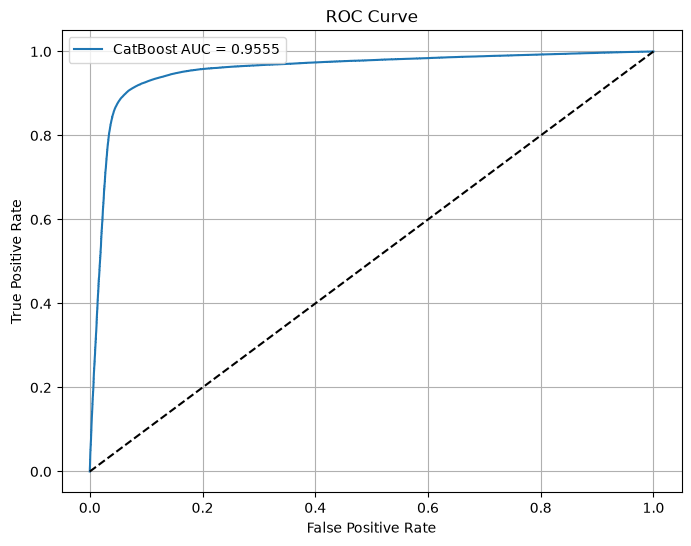

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"CatBoost AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd

# Load the dataset you want to predict on
new_data = pd.read_csv("test.csv")

# Select the same feature columns used during training
X_new = new_data[X_train.columns]

# Predict the target
predictions = model.predict(X_new)

# Get probabilities for the positive class
probabilities = model.predict_proba(X_new)[:, 1]

# Add predictions to the dataset
new_data["Satisfaction"] = predictions
new_data["Prediction_Probability"] = probabilities

# Save the results
new_data.to_csv("predictions.csv", index=False)

In [ ]:
new_data

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,Predicted_Target,Prediction_Probability
0,699635,25,1197,4,4,4,2,3,4,3,...,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco,False,0.233529
1,699636,36,829,5,5,5,5,5,4,5,...,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco,True,0.847460
2,699637,45,472,4,5,5,5,4,4,4,...,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco,True,0.889563
3,699638,45,762,2,2,2,5,3,2,3,...,4,3,0,0.0,Female,disloyal Customer,Business travel,Business,False,0.038394
4,699639,34,594,1,2,1,1,2,1,2,...,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus,False,0.058713
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299839,999474,32,1725,3,1,3,3,3,3,3,...,1,3,0,0.0,Female,Loyal Customer,Business travel,Business,False,0.071584
299840,999475,24,1325,3,3,3,4,3,3,3,...,5,3,0,0.0,Female,disloyal Customer,Business travel,Eco,False,0.086717
299841,999476,33,190,4,5,4,3,3,4,3,...,2,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False,0.306556
299842,999477,59,678,3,5,3,2,4,3,5,...,4,5,4,0.0,Male,Loyal Customer,Personal Travel,Eco,False,0.031013


In [ ]:
new_data[['id','Satisfaction']].to_csv("predictions.csv",index=False)